# Assignment 2: From Trees to Neural Networks

**Task:** Predict whether a bank client subscribes to a term deposit (`y` in `{no, yes}`) on the UCI Bank Marketing data (`bank-additional-full.csv`).

This notebook implements an end-to-end comparison of two model families:

1. Data preparation (audit, cleaning, stratified split, leakage-safe preprocessing)
2. Gradient-boosted decision trees (XGBoost)
3. Multi-layer perceptron (scikit-learn)
4. One-time test evaluation and comparison


## 0. Setup

Import the libraries used below and fix the constants that make the work reproducible.

The modeling dataset is `bank-additional-full.csv` (semicolon-separated). A stratified 70/15/15 train/validation/test split is built from it so validation can drive early stopping and model selection while the test partition stays held out until Section 7.


In [1]:
import os
import platform
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import xgboost as xgb
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_FILE = "bank-additional-full.csv"
TARGET = "y"
POSITIVE_LABEL = "yes"
LEAKAGE_COLUMNS = ["duration"]
PDAYS_NO_CONTACT = 999
PDAYS_NO_CONTACT_ENCODED = -1


def cpu_model() -> str:
    """CPU model name from /proc/cpuinfo (Linux/Colab); falls back to platform.processor()."""
    try:
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or "unknown"


print(f"Python:       {platform.python_version()}")
print(f"pandas:       {pd.__version__}")
print(f"numpy:        {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"xgboost:      {xgb.__version__}")
print(f"matplotlib:   {matplotlib.__version__}")
print(f"Platform:     {platform.platform()}")
print(f"CPU model:    {cpu_model()}")
print(f"CPU cores:    {os.cpu_count()}")
print(f"RANDOM_STATE: {RANDOM_STATE}")

Python:       3.13.18
pandas:       2.2.3
numpy:        2.4.6
scikit-learn: 1.6.1
xgboost:      3.4.1
matplotlib:   3.10.0
Platform:     Linux-6.6.159+-x86_64-with-glibc2.39
CPU model:    Intel(R) Xeon(R) CPU @ 2.20GHz
CPU cores:    2
RANDOM_STATE: 42


### 0.1 Locate the data

Prefer a local `bank-additional-full.csv` in the notebook working directory (Colab upload). If it is missing, load the file from the course GitHub link:
[assignment2/data/bank-additional-full.csv](https://github.com/2004Luci/AML/tree/main/assignment2/data).


In [2]:
LOCAL_DATA = Path(DATA_FILE)
GITHUB_DATA_URL = (
    "https://raw.githubusercontent.com/2004Luci/AML/main/assignment2/data/bank-additional-full.csv"
)

if LOCAL_DATA.exists():
    DATA_PATH = LOCAL_DATA
    print(f"Using local file: {DATA_PATH.resolve()}")
else:
    DATA_PATH = GITHUB_DATA_URL
    print("Local bank-additional-full.csv not found; using GitHub fallback:")
    print(DATA_PATH)

Using local file: /content/bank-additional-full.csv


## 1. Data audit

Load the Bank Marketing data and establish its structure, feature types, target distribution, and missing/special-value profile. These observations drive the cleaning decisions that follow.


In [3]:
df = pd.read_csv(DATA_PATH, sep=";")
print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")
df.head()

Rows: 41,188  Columns: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 1.1 Feature types

In [4]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in df.columns if c not in numeric_cols and c != TARGET]

feature_types = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
}).drop(index=TARGET)
feature_types["type"] = np.where(feature_types.index.isin(numeric_cols), "numeric", "nominal categorical")

print(f"Numeric columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")
feature_types

Numeric columns (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical columns (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


,dtype,n_unique,type
age,int64,78,numeric
job,object,12,nominal categorical
marital,object,4,nominal categorical
education,object,8,nominal categorical
default,object,3,nominal categorical
housing,object,3,nominal categorical
loan,object,3,nominal categorical
contact,object,2,nominal categorical
month,object,10,nominal categorical
day_of_week,object,5,nominal categorical


**Interpretation.** There are 20 predictors: 10 numeric (`age`, `duration`, `campaign`, `pdays`, `previous`, and five macroeconomic indicators) and 10 nominal categorical columns with 2 to 12 levels each. No categorical column has a natural order the models should exploit, so all are one-hot encoded in Section 4. `duration` is listed for the audit only; it is removed in Section 2.


### 1.2 Target distribution

In [5]:
target_counts = df[TARGET].value_counts()
target_share = df[TARGET].value_counts(normalize=True)
pd.DataFrame({"count": target_counts, "proportion": target_share.round(4)})

,count,proportion
y,,
no,36548,0.8873
yes,4640,0.1127


**Interpretation.** 36,548 clients did not subscribe (88.73%) and 4,640 did (11.27%). The positive class is rare, so a model that always predicts "no" already reaches about 88.7% accuracy. This is why the split is stratified and why Average Precision — how well subscribers are ranked above non-subscribers — is the primary metric.


### 1.3 Missing and special values

In [6]:
# pandas nulls vs. the dataset's literal "unknown" category
null_counts = df.isna().sum()
print(f"Total pandas-null cells: {int(null_counts.sum())}")

unknown_summary = pd.DataFrame({
    "unknown_count": [(df[c] == "unknown").sum() for c in categorical_cols],
}, index=categorical_cols)
unknown_summary["unknown_pct"] = (100 * unknown_summary["unknown_count"] / len(df)).round(2)
unknown_summary.sort_values("unknown_count", ascending=False)

Total pandas-null cells: 0


,unknown_count,unknown_pct
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19
contact,0,0.00
month,0,0.00
day_of_week,0,0.00
poutcome,0,0.00


In [7]:
no_contact = df["pdays"] == PDAYS_NO_CONTACT
print(f"pdays == {PDAYS_NO_CONTACT}: {no_contact.sum():,} rows ({no_contact.mean():.2%})")
print("pdays range when a previous contact exists:",
      df.loc[~no_contact, "pdays"].min(), "to", df.loc[~no_contact, "pdays"].max())
print()
print(pd.crosstab(no_contact.rename("pdays == 999"), df["poutcome"]))

pdays == 999: 39,673 rows (96.32%)
pdays range when a previous contact exists: 0 to 27

poutcome      failure  nonexistent  success
pdays == 999                               
False             142            0     1373
True             4110        35563        0


In [8]:
print(f"Exact duplicate rows (all columns):           {df.duplicated().sum():,}")
print(f"Duplicate rows after excluding duration:      {df.drop(columns=LEAKAGE_COLUMNS).duplicated().sum():,}")
print(f"Rows where default == 'yes':                  {(df['default'] == 'yes').sum():,}")

Exact duplicate rows (all columns):           12
Duplicate rows after excluding duration:      1,784
Rows where default == 'yes':                  3


**Audit findings.**

- 41,188 rows × 21 columns: 10 numeric predictors, 10 nominal categoricals, and target `y`.
- No pandas-null values. Missingness appears as the literal category `"unknown"` in six columns, most heavily in `default` (~20.9% of rows). Whether `"unknown"` carries signal about the target is checked on training rows only, after the split (Section 3.1).
- `pdays = 999` is the dataset's sentinel for *no recorded days since a previous-campaign contact*, not 999 elapsed days (~96.3% of rows). Real values range from 0 to 27. Every `poutcome = "success"` row has a real `pdays` and every `"nonexistent"` row has `pdays = 999`, but 4,110 `"failure"` rows with `previous > 0` also have `pdays = 999`.
- 12 exact duplicate rows. Without a client identifier there is no way to tell whether they are repeats or different clients with identical attributes.


## 2. Cleaning decisions and target definition

| Item | Decision | Reason |
|---|---|---|
| Target | `y = "yes"` → 1, `"no"` → 0 | Positive class defined by the handout |
| `duration` | Dropped from predictors | Call length is known only after the call ends; using it would leak information unavailable at prediction time |
| `pdays = 999` | Indicator `pdays_recorded` (1 when a real day count is present); `pdays` set to −1 when it is 999 | 999 is a sentinel, not an elapsed number of days. Leaving it would place these clients far from real values (0–27). Because some rows with 999 still have `previous > 0`, the indicator records whether a day count is present; contact count stays in `previous`. −1 sits just outside the valid range so both models can separate the two cases |
| Literal `"unknown"` | Kept as its own category and one-hot encoded | It is a recorded value, not a blank cell, and on training rows its subscription rate differs from known values (Section 3.1). Imputing the mode would erase that signal |
| Missing values (NaN) | No imputation needed | The audit found no pandas-null values |
| Duplicates | All rows kept | Only 12 exact duplicates (0.03%) and no client ID to confirm they are repeats |
| `default = "yes"` | Kept | Only 3 rows; the encoder ignores the level if it never appears in training |

These steps are deterministic, row-by-row rules that learn nothing from the data, so applying them before the split does not leak information.


In [9]:
def prepare_features(raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Deterministic, row-wise cleaning only (no statistics learned from the data)."""
    data = raw.copy()
    valid_labels = {"no", POSITIVE_LABEL}
    invalid = ~data[TARGET].isin(valid_labels)
    if invalid.any():
        raise ValueError(f"{TARGET} must be one of {sorted(valid_labels)}; found "
                         f"{data.loc[invalid, TARGET].unique().tolist()} in {int(invalid.sum())} rows")
    y = (data[TARGET] == POSITIVE_LABEL).astype(int).rename("target")

    data["pdays_recorded"] = (data["pdays"] != PDAYS_NO_CONTACT).astype(int)
    data["pdays"] = data["pdays"].where(data["pdays_recorded"] == 1, PDAYS_NO_CONTACT_ENCODED)

    X = data.drop(columns=[TARGET, *LEAKAGE_COLUMNS])
    return X, y


X, y = prepare_features(df)

assert "duration" not in X.columns
assert TARGET not in X.columns
assert (X.loc[X["pdays_recorded"] == 0, "pdays"] == PDAYS_NO_CONTACT_ENCODED).all()

print(f"X: {X.shape}  y: {y.shape}  positive rate: {y.mean():.4f}")
X[["pdays", "pdays_recorded", "previous", "poutcome"]].head()

X: (41188, 20)  y: (41188,)  positive rate: 0.1127


,pdays,pdays_recorded,previous,poutcome
0,-1,0,0,nonexistent
1,-1,0,0,nonexistent
2,-1,0,0,nonexistent
3,-1,0,0,nonexistent
4,-1,0,0,nonexistent


In [10]:
CATEGORICAL_FEATURES = [
    "job", "marital", "education", "default", "housing", "loan",
    "contact", "month", "day_of_week", "poutcome",
]
NUMERIC_FEATURES = [
    "age", "campaign", "pdays", "previous", "pdays_recorded",
    "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed",
]

assert set(CATEGORICAL_FEATURES) | set(NUMERIC_FEATURES) == set(X.columns)
assert not set(CATEGORICAL_FEATURES) & set(NUMERIC_FEATURES)
print(f"{len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical = {X.shape[1]} predictors")

10 numeric + 10 categorical = 20 predictors


## 3. Stratified 70/15/15 train / validation / test split

The split is made in two stages with `random_state = 42`, stratified on the target each time so all three partitions keep the same positive-class rate.

- **Train (70%)** — fit preprocessing and models.
- **Validation (15%)** — XGBoost early stopping and configuration selection by validation Average Precision.
- **Test (15%)** — used once, after both final configurations are fixed.

The same split rows are reused for every GBDT and MLP experiment.


In [11]:
TRAIN_SIZE, VALID_SIZE, TEST_SIZE = 0.70, 0.15, 0.15

# Stage 1: 70% train vs. 30% holdout. Stage 2: split the holdout 50/50 into validation and test.
X_train, X_hold, y_train, y_hold = train_test_split(
    X, y, train_size=TRAIN_SIZE, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_hold, y_hold, test_size=TEST_SIZE / (VALID_SIZE + TEST_SIZE), stratify=y_hold, random_state=RANDOM_STATE
)

# Test labels are not read here; the test positive count and rate are computed only in Section 7.
split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_valid), len(y_test)],
    "share": [len(y_train) / len(y), len(y_valid) / len(y), len(y_test) / len(y)],
    "positives": pd.array([y_train.sum(), y_valid.sum(), pd.NA], dtype="Int64"),
    "positive_rate": [y_train.mean(), y_valid.mean(), np.nan],
}, index=["train", "validation", "test (held out)"]).round(4)
split_summary

,rows,share,positives,positive_rate
train,28831,0.70,3248,0.1127
validation,6178,0.15,696,0.1127
test (held out),6179,0.15,<NA>,NaN


In [12]:
train_idx, valid_idx, test_idx = set(X_train.index), set(X_valid.index), set(X_test.index)

assert not train_idx & valid_idx and not train_idx & test_idx and not valid_idx & test_idx
assert len(train_idx | valid_idx | test_idx) == len(X)
assert X_train.index.equals(y_train.index) and X_valid.index.equals(y_valid.index) and X_test.index.equals(y_test.index)
print("Splits are disjoint, cover every row, and X/y indices are aligned.")

Splits are disjoint, cover every row, and X/y indices are aligned.


**Interpretation.**

- The positive-class rate is essentially identical in train and validation, so later differences reflect the models rather than an uneven split.
- Test labels are not inspected here. Stratification already fixes the test rate by construction; the test positive count is reported only in Section 7, after both configurations are selected.
- A random split measures performance on clients from the same historical campaigns; it does not test generalization to future campaigns. The data are a 2008–2010 Portuguese bank benchmark, so scores here are not evidence of current banking performance.


### 3.1 Is `"unknown"` informative? (training rows only)

This check uses the target, so it is computed on the training split only.


In [13]:
# Subscription rate when a field is "unknown" vs. known, using training rows only.
rows = []
for col in unknown_summary.index[unknown_summary["unknown_count"] > 0]:
    is_unknown = X_train[col] == "unknown"
    rows.append({
        "column": col,
        "train_unknown_rows": int(is_unknown.sum()),
        "positive_rate_unknown": y_train[is_unknown].mean(),
        "positive_rate_known": y_train[~is_unknown].mean(),
    })
pd.DataFrame(rows).set_index("column").round(4)

,train_unknown_rows,positive_rate_unknown,positive_rate_known
column,,,
job,240,0.1250,0.1126
marital,58,0.1897,0.1125
education,1234,0.1459,0.1112
default,6051,0.0527,0.1286
housing,707,0.1160,0.1126
loan,707,0.1160,0.1126


**Interpretation.** On training rows, clients with `default = "unknown"` subscribe at about 5.3%, versus 12.9% when `default` is known. Unknown `education` and `marital` values have higher rates than known values (~14.6% and ~19.0% versus ~11%), although `marital` has only 58 unknown training rows. `"unknown"` therefore carries signal, which supports keeping it as its own category rather than imputing a mode.


## 4. Leakage-safe preprocessing

Learned preprocessing is fitted on `X_train` only and then applied unchanged to validation and test:

- **One-hot encoding** for all 10 nominal categorical columns, with `handle_unknown="ignore"` so a category that never appears in training becomes an all-zero row instead of an error.
- **Standard scaling** of numeric columns for the MLP only. Gradient-based networks train poorly when inputs have very different scales (for example `nr.employed` around 5,000 versus `pdays_recorded` in `{0, 1}`). Tree splits depend only on value order, so the GBDT input keeps the raw numeric values.

Both inputs contain the same columns and rows; the only model-specific difference is numeric scaling. Each `preprocessing_sec` value measures `fit_transform(X_train)` plus `transform` on validation and test, and is recorded separately from model fitting time.


In [14]:
def make_preprocessor(scale_numeric: bool) -> ColumnTransformer:
    numeric_step = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer(
        transformers=[
            ("num", numeric_step, NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def fit_transform_splits(preprocessor: ColumnTransformer):
    """Fit on training rows only; reuse the fitted transformer for validation and test."""
    start = time.perf_counter()
    train_t = preprocessor.fit_transform(X_train)
    valid_t = preprocessor.transform(X_valid)
    test_t = preprocessor.transform(X_test)
    return train_t, valid_t, test_t, time.perf_counter() - start


tree_preprocessor = make_preprocessor(scale_numeric=False)
mlp_preprocessor = make_preprocessor(scale_numeric=True)

X_train_tree, X_valid_tree, X_test_tree, tree_preprocess_sec = fit_transform_splits(tree_preprocessor)
X_train_mlp, X_valid_mlp, X_test_mlp, mlp_preprocess_sec = fit_transform_splits(mlp_preprocessor)


pd.DataFrame({
    "train": [X_train_tree.shape, X_train_mlp.shape],
    "validation": [X_valid_tree.shape, X_valid_mlp.shape],
    "test": [X_test_tree.shape, X_test_mlp.shape],
    "preprocessing_sec": [round(tree_preprocess_sec, 4), round(mlp_preprocess_sec, 4)],
}, index=["GBDT input", "MLP input"])

,train,validation,test,preprocessing_sec
GBDT input,"(28831, 63)","(6178, 63)","(6179, 63)",0.7901
MLP input,"(28831, 63)","(6178, 63)","(6179, 63)",0.7580


In [15]:
# 1. Both models see the same encoded columns (same underlying information).
assert list(X_train_tree.columns) == list(X_train_mlp.columns)

# 2. No missing values after preprocessing.
for frame in [X_train_tree, X_valid_tree, X_test_tree, X_train_mlp, X_valid_mlp, X_test_mlp]:
    assert not frame.isna().any().any()

# 3. Tree numeric columns are unchanged; MLP numeric columns are standardized with training statistics.
assert np.allclose(X_train_tree[NUMERIC_FEATURES].to_numpy(), X_train[NUMERIC_FEATURES].to_numpy())

scaling_check = pd.DataFrame({
    "train_mean": X_train_mlp[NUMERIC_FEATURES].mean(),
    "train_std": X_train_mlp[NUMERIC_FEATURES].std(ddof=0),
    "valid_mean": X_valid_mlp[NUMERIC_FEATURES].mean(),
    "test_mean": X_test_mlp[NUMERIC_FEATURES].mean(),
}).round(4)

n_onehot = len(X_train_tree.columns) - len(NUMERIC_FEATURES)
print(f"Encoded features: {X_train_tree.shape[1]} ({len(NUMERIC_FEATURES)} numeric + {n_onehot} one-hot)")
print("Categories with no training rows (ignored if seen later):",
      [f"{col}={val}" for col in CATEGORICAL_FEATURES for val in X[col].unique()
       if val not in set(X_train[col])] or "none")
scaling_check

Encoded features: 63 (10 numeric + 53 one-hot)
Categories with no training rows (ignored if seen later): none


,train_mean,train_std,valid_mean,test_mean
age,-0.0,1.0,-0.0017,0.0097
campaign,-0.0,1.0,0.0301,-0.0056
pdays,0.0,1.0,-0.0189,-0.0207
previous,0.0,1.0,-0.0283,-0.0129
pdays_recorded,-0.0,1.0,-0.0237,-0.0204
emp.var.rate,-0.0,1.0,0.0022,-0.0039
cons.price.idx,0.0,1.0,0.0020,-0.0062
cons.conf.idx,-0.0,1.0,-0.0058,0.0076
euribor3m,0.0,1.0,0.0085,-0.0003
nr.employed,0.0,1.0,0.0126,-0.0024


**Interpretation.** Both models receive the same encoded features, and nothing is missing. The scaled MLP features have mean 0 and standard deviation 1 on the training rows only; validation and test means are close to, but not exactly, 0. That small difference is expected: the scaler reused training statistics instead of being refit on held-out data.


## 5. Gradient-boosted decision trees (XGBoost)

All runs use `xgboost.XGBClassifier(tree_method="hist")` on the GBDT input from Section 4 (one-hot, unscaled numerics), with the same training and validation rows.

**Fixed settings**

- `n_estimators = 5000` as an upper limit, with `early_stopping_rounds = 50` and `eval_metric = "logloss"` set in the constructor.
- `eval_set = [(train), (validation)]`: binary log loss is tracked on both; validation, listed last, controls early stopping.
- `random_state = 42`, `device = "cpu"`; remaining hyperparameters at XGBoost defaults.

**Two metrics.** Validation *log loss* decides when to stop adding trees within a run. Validation *Average Precision* (from `predict_proba`, via `average_precision_score`) compares configurations and selects the final model. The test set is not used here.

**Controlled experiments (8 configurations)**

| Phase | Varied | Held fixed |
|---|---|---|
| A | `learning_rate` in `{0.01, 0.1, 0.3}` | `max_depth = 4`, `subsample = 1.0` |
| B | `max_depth` in `{2, 4, 6, 8}` | best learning rate from A, `subsample = 1.0` |
| C | `subsample` in `{1.0, 0.8, 0.6}` (regularization) | best learning rate and depth |

Phases share their reference configuration, so each comparison changes one setting at a time.


In [16]:
GBDT_N_ESTIMATORS = 5000          # upper limit; early stopping decides the actual number of trees
GBDT_EARLY_STOPPING_ROUNDS = 50   # stop after 50 rounds without validation log-loss improvement
GBDT_BASE_PARAMS = {"learning_rate": 0.1, "max_depth": 4, "subsample": 1.0}

gbdt_models: dict[str, xgb.XGBClassifier] = {}
gbdt_records: list[dict] = []


def fit_gbdt(config_id: str, phase: str, **overrides) -> dict:
    """Train one XGBoost configuration with validation-based early stopping and record the result."""
    params = {**GBDT_BASE_PARAMS, **overrides}
    model = xgb.XGBClassifier(
        tree_method="hist",
        device="cpu",  # explicit: all timings are CPU-only
        n_estimators=GBDT_N_ESTIMATORS,
        early_stopping_rounds=GBDT_EARLY_STOPPING_ROUNDS,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **params,
    )
    start = time.perf_counter()
    # Validation is listed last, so it controls early stopping.
    model.fit(X_train_tree, y_train, eval_set=[(X_train_tree, y_train), (X_valid_tree, y_valid)], verbose=False)
    fit_sec = time.perf_counter() - start

    history = model.evals_result()
    best = model.best_iteration
    trees_built = len(history["validation_1"]["logloss"])
    train_loss = history["validation_0"]["logloss"][best]
    valid_loss = history["validation_1"]["logloss"][best]
    # With early stopping, predict_proba uses the trees up to best_iteration.
    valid_ap = average_precision_score(y_valid, model.predict_proba(X_valid_tree)[:, 1])

    record = {
        "config": config_id,
        "phase": phase,
        **params,
        "best_iteration": best,
        "trees_built": trees_built,
        # Cap-limited only if the run ended at the cap before early stopping could trigger.
        "hit_cap": trees_built == GBDT_N_ESTIMATORS and trees_built - 1 - best < GBDT_EARLY_STOPPING_ROUNDS,
        "train_logloss": train_loss,
        "valid_logloss": valid_loss,
        "logloss_gap": valid_loss - train_loss,
        "valid_AP": valid_ap,
        "fit_sec": fit_sec,
    }
    # Re-running a phase replaces its earlier record and model under the same ID.
    gbdt_records[:] = [r for r in gbdt_records if r["config"] != config_id]
    gbdt_models[config_id] = model
    gbdt_records.append(record)
    return record


def gbdt_table(records: list[dict]) -> pd.DataFrame:
    return pd.DataFrame(records).set_index("config").round(4)

### 5.1 Phase A — learning rate

In [17]:
for i, lr in enumerate([0.01, 0.1, 0.3], start=1):
    fit_gbdt(f"G{i}", "A: learning rate", learning_rate=lr)

phase_a = [r for r in gbdt_records if r["phase"] == "A: learning rate"]
best_lr = max(phase_a, key=lambda r: r["valid_AP"])["learning_rate"]
print(f"Learning rate carried forward (best validation AP in phase A): {best_lr}")
gbdt_table(phase_a)

Learning rate carried forward (best validation AP in phase A): 0.01


,phase,learning_rate,max_depth,subsample,best_iteration,trees_built,hit_cap,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
G1,A: learning rate,0.01,4,1.0,1292,1343,False,0.2596,0.2665,0.0069,0.4906,20.7787
G2,A: learning rate,0.10,4,1.0,181,232,False,0.2538,0.2662,0.0124,0.4882,2.2892
G3,A: learning rate,0.30,4,1.0,49,100,False,0.2550,0.2667,0.0117,0.4894,1.1082


### 5.2 Phase B — tree depth

In [18]:
for i, depth in enumerate([2, 6, 8], start=4):
    fit_gbdt(f"G{i}", "B: max depth", learning_rate=best_lr, max_depth=depth)

# Depth 4 at the chosen learning rate was already trained in phase A and is reused as the reference.
depth_comparison = [r for r in gbdt_records if r["learning_rate"] == best_lr and r["subsample"] == 1.0]
best_depth = max(depth_comparison, key=lambda r: r["valid_AP"])["max_depth"]
print(f"Max depth carried forward (best validation AP among depths): {best_depth}")
gbdt_table(sorted(depth_comparison, key=lambda r: r["max_depth"]))

Max depth carried forward (best validation AP among depths): 4


,phase,learning_rate,max_depth,subsample,best_iteration,trees_built,hit_cap,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
G4,B: max depth,0.01,2,1.0,3136,3187,False,0.2683,0.2678,-0.0005,0.4822,33.2428
G1,A: learning rate,0.01,4,1.0,1292,1343,False,0.2596,0.2665,0.0069,0.4906,20.7787
G5,B: max depth,0.01,6,1.0,428,479,False,0.2539,0.2657,0.0118,0.4898,6.1238
G6,B: max depth,0.01,8,1.0,411,462,False,0.2352,0.2665,0.0313,0.4828,9.3859


### 5.3 Phase C — row subsampling

`subsample` trains each tree on a random fraction of the training rows. Adding randomness makes individual trees less able to fit noise in the training set.


In [19]:
for i, subsample in enumerate([0.8, 0.6], start=7):
    fit_gbdt(f"G{i}", "C: subsample", learning_rate=best_lr, max_depth=best_depth, subsample=subsample)

# subsample = 1.0 at the chosen learning rate and depth is the reference from earlier phases.
subsample_comparison = [r for r in gbdt_records if r["learning_rate"] == best_lr and r["max_depth"] == best_depth]
gbdt_table(sorted(subsample_comparison, key=lambda r: -r["subsample"]))

,phase,learning_rate,max_depth,subsample,best_iteration,trees_built,hit_cap,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
G1,A: learning rate,0.01,4,1.0,1292,1343,False,0.2596,0.2665,0.0069,0.4906,20.7787
G7,C: subsample,0.01,4,0.8,862,913,False,0.2605,0.2660,0.0054,0.4923,11.5394
G8,C: subsample,0.01,4,0.6,897,948,False,0.2596,0.2656,0.0060,0.4917,9.3483


### 5.4 All configurations and selection

The final GBDT is the configuration with the highest validation AP.


In [20]:
gbdt_results = gbdt_table(gbdt_records)
# Select on unrounded validation AP from gbdt_records (gbdt_table rounds to 4 decimals).
selected_record = max(gbdt_records, key=lambda r: r["valid_AP"])
GBDT_SELECTED_ID = selected_record["config"]
gbdt_selected = gbdt_models[GBDT_SELECTED_ID]

print(f"Configurations tried: {len(gbdt_results)}")
print(f"Runs that reached the n_estimators cap without early stopping: {int(gbdt_results['hit_cap'].sum())}")
print(f"Selected GBDT: {GBDT_SELECTED_ID} "
      f"(learning_rate={selected_record['learning_rate']}, "
      f"max_depth={selected_record['max_depth']}, "
      f"subsample={selected_record['subsample']}) "
      f"— validation AP {selected_record['valid_AP']:.4f}")
print(f"Validation AP range across configurations: "
      f"{min(r['valid_AP'] for r in gbdt_records):.4f} – "
      f"{max(r['valid_AP'] for r in gbdt_records):.4f}")
gbdt_results



Configurations tried: 8
Runs that reached the n_estimators cap without early stopping: 0
Selected GBDT: G7 (learning_rate=0.01, max_depth=4, subsample=0.8) — validation AP 0.4923
Validation AP range across configurations: 0.4822 – 0.4923


,phase,learning_rate,max_depth,subsample,best_iteration,trees_built,hit_cap,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
G1,A: learning rate,0.01,4,1.0,1292,1343,False,0.2596,0.2665,0.0069,0.4906,20.7787
G2,A: learning rate,0.10,4,1.0,181,232,False,0.2538,0.2662,0.0124,0.4882,2.2892
G3,A: learning rate,0.30,4,1.0,49,100,False,0.2550,0.2667,0.0117,0.4894,1.1082
G4,B: max depth,0.01,2,1.0,3136,3187,False,0.2683,0.2678,-0.0005,0.4822,33.2428
G5,B: max depth,0.01,6,1.0,428,479,False,0.2539,0.2657,0.0118,0.4898,6.1238
G6,B: max depth,0.01,8,1.0,411,462,False,0.2352,0.2665,0.0313,0.4828,9.3859
G7,C: subsample,0.01,4,0.8,862,913,False,0.2605,0.2660,0.0054,0.4923,11.5394
G8,C: subsample,0.01,4,0.6,897,948,False,0.2596,0.2656,0.0060,0.4917,9.3483


### 5.5 Learning curves

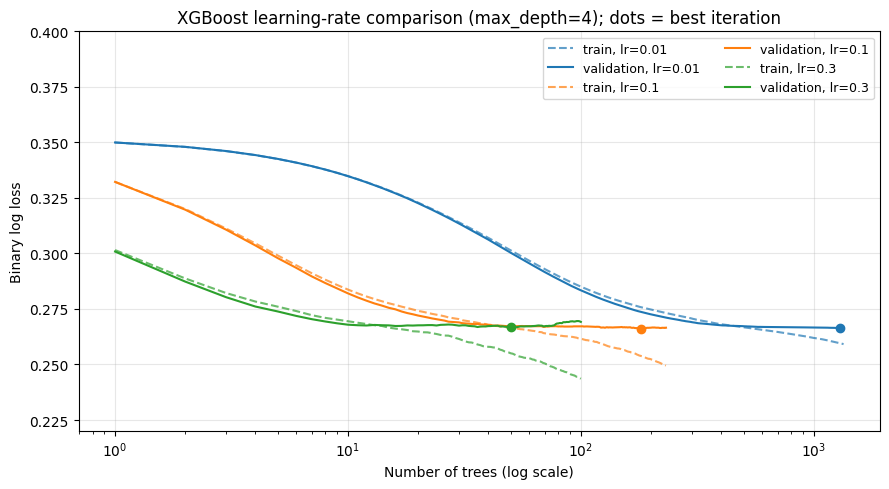

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = {0.01: "tab:blue", 0.1: "tab:orange", 0.3: "tab:green"}
for record in phase_a:
    model = gbdt_models[record["config"]]
    history = model.evals_result()
    lr = record["learning_rate"]
    rounds = np.arange(1, len(history["validation_1"]["logloss"]) + 1)  # 1-based so round 1 shows on a log axis
    ax.plot(rounds, history["validation_0"]["logloss"], color=colors[lr], linestyle="--", alpha=0.7, label=f"train, lr={lr}")
    ax.plot(rounds, history["validation_1"]["logloss"], color=colors[lr], label=f"validation, lr={lr}")
    ax.scatter(record["best_iteration"] + 1, record["valid_logloss"], color=colors[lr], zorder=5)

ax.set_xscale("log")
ax.set_ylim(0.22, 0.40)
ax.set_xlabel("Number of trees (log scale)")
ax.set_ylabel("Binary log loss")
ax.set_title(f"XGBoost learning-rate comparison (max_depth={GBDT_BASE_PARAMS['max_depth']}); dots = best iteration")
ax.legend(ncol=2, fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fig_gbdt_learning_rates.png", dpi=200, bbox_inches="tight")
plt.show()

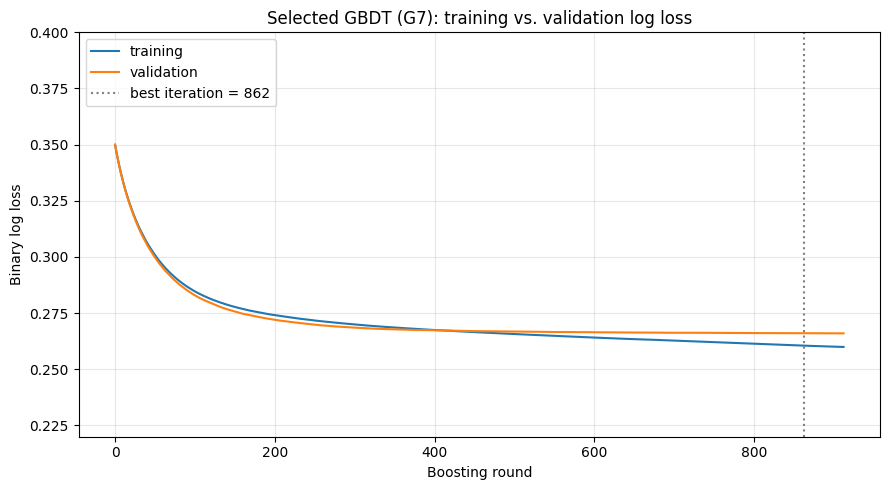

In [22]:
history = gbdt_selected.evals_result()
best_it = gbdt_selected.best_iteration

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(history["validation_0"]["logloss"], label="training")
ax.plot(history["validation_1"]["logloss"], label="validation")
ax.axvline(best_it, color="gray", linestyle=":", label=f"best iteration = {best_it}")
ax.set_ylim(0.22, 0.40)
ax.set_xlabel("Boosting round")
ax.set_ylabel("Binary log loss")
ax.set_title(f"Selected GBDT ({GBDT_SELECTED_ID}): training vs. validation log loss")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fig_gbdt_selected_logloss.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.6 Feature importance

Importance measure: **total gain** — the sum of improvements in the training objective from splits on a feature across the trees used for prediction (boosting rounds `0` through `best_iteration`, inclusive), shown as a share of that total. One-hot encoding splits each categorical into separate columns (for example `poutcome_success`).


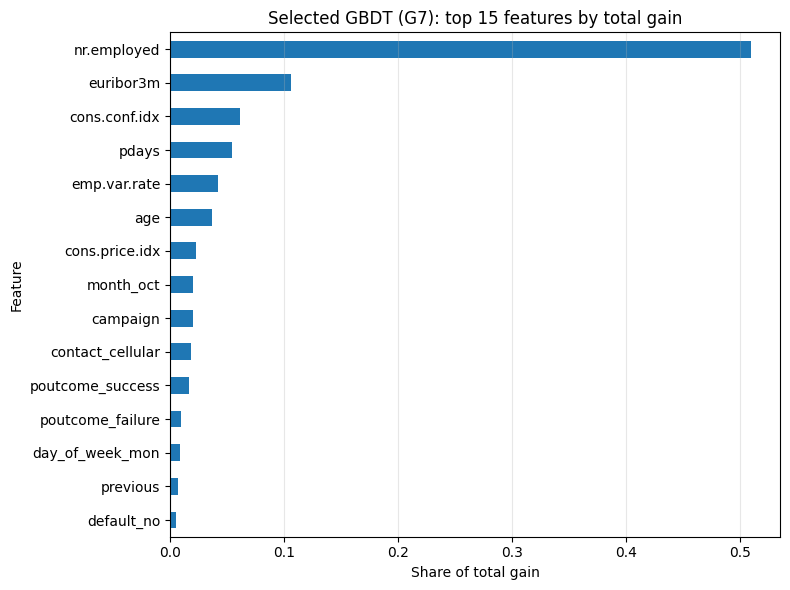

Trees included: 0..862 (best_iteration inclusive); booster also has 50 early-stopping extra rounds not used here
Features used in at least one split: 58 of 63
Top feature share: nr.employed = 0.5093


,gain_share
Feature,
nr.employed,0.5093
euribor3m,0.1058
cons.conf.idx,0.0612
pdays,0.054
emp.var.rate,0.0425
age,0.0367
cons.price.idx,0.023
month_oct,0.0204
campaign,0.0203


In [23]:
# Importance over trees used for prediction only: Tree index is 0-based and
# best_iteration is inclusive, matching predict_proba under early stopping.
# Use total_gain (sum of split gains), not average gain per split.
booster = gbdt_selected.get_booster()
best_it = gbdt_selected.best_iteration
trees = booster.trees_to_dataframe()
split_gains = trees.loc[(trees["Tree"] <= best_it) & (trees["Feature"] != "Leaf")]
gain = split_gains.groupby("Feature")["Gain"].sum()
gain_share = (gain / gain.sum()).sort_values(ascending=False)
TOP_N = 15

fig, ax = plt.subplots(figsize=(8, 6))
gain_share.head(TOP_N).iloc[::-1].plot.barh(ax=ax, color="tab:blue")
ax.set_xlabel("Share of total gain")
ax.set_title(f"Selected GBDT ({GBDT_SELECTED_ID}): top {TOP_N} features by total gain")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("fig_gbdt_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Trees included: 0..{best_it} (best_iteration inclusive); "
      f"booster also has {booster.num_boosted_rounds() - (best_it + 1)} early-stopping extra rounds not used here")
print(f"Features used in at least one split: {len(gain)} of {X_train_tree.shape[1]}")
print(f"Top feature share: {gain_share.index[0]} = {gain_share.iloc[0]:.4f}")
gain_share.head(TOP_N).round(4).to_frame("gain_share")



**Interpretation.**

- **Learning rate mainly changes how fast boosting converges, not where it ends up.** All three rates reach similar validation AP (~0.488–0.491). The best validation loss is reached after about 1,300 trees at `0.01`, about 180 at `0.1`, and about 50 at `0.3`. Larger steps reach the minimum sooner and then overfit sooner: at `0.3`, training loss keeps falling after validation loss has bottomed out, and early stopping ends the run. The AP edge of `0.01` is only about 0.001–0.002 — within noise — but under the selection rule it is carried into phases B and C.
- **Depth controls the bias–variance trade-off.** Depth 2 has the highest training and validation loss and needs more than 3,000 trees: it underfits (high bias) and converges slowly. As depth increases, training loss falls faster than validation loss, so the train–validation gap widens from about 0.007 at depth 4 to about 0.03 at depth 8 (higher variance). Validation AP peaks at depth 4–6 and drops at depth 8.
- **Row subsampling has a small regularizing effect.** With `subsample` 0.8 or 0.6, the train–validation gap shrinks slightly and validation AP rises slightly. Under the unrounded validation-AP rule, `subsample = 0.8` is selected among the eight configurations.
- **The differences are small.** Validation AP varies by only about 0.01 across all configurations. With ~700 validation positives, gaps this small may partly reflect sampling noise; the selected configuration is a reasonable choice under a fixed rule rather than proof that it is uniquely best.
- **The selected model's curves** show both losses falling quickly over the first ~200 trees. After roughly 400 trees validation loss is almost flat while training loss keeps decreasing; early stopping keeps the trees up to the best validation iteration.
- **Feature importance is dominated by macroeconomic indicators**, especially `nr.employed` (~half of total gain among trees through `best_iteration`), followed by other macros (`euribor3m`, `cons.conf.idx`, `emp.var.rate`), `pdays`, and campaign-history features such as `poutcome_success`. The macros are strongly correlated and change with campaign calendar period, so gain can be split among them somewhat arbitrarily and part of their importance reflects *when* a call happened. This is an association learned by the model, not a causal effect.


## 6. Multi-layer perceptron (scikit-learn)

All runs use `sklearn.neural_network.MLPClassifier(solver="adam")` on the MLP input from Section 4 (one-hot categoricals plus numerics standardized with training statistics), with the same training and validation rows as the GBDT experiments.

**Fixed settings**

- `max_iter = 200` epochs as the training budget for every configuration.
- `early_stopping = False`: all training rows update weights, and the external validation set is used only to compare configurations. Training can still end before `max_iter` when the training loss improves by less than `tol = 1e-4` for 10 consecutive epochs. A run that uses the full budget without meeting that criterion raises a `ConvergenceWarning`; these are captured and recorded in the `converged` column.
- `activation = "relu"`, `batch_size = "auto"` (200 rows), `random_state = 42`; remaining hyperparameters at scikit-learn defaults.

**What is measured.** `loss_curve_` is the training loss per epoch and includes the L2 penalty, so its level depends on `alpha`. After training, `train_logloss` and `valid_logloss` are computed from `predict_proba` without the penalty, which makes them comparable across configurations and with the GBDT table. Validation Average Precision selects the final configuration. The test set is not used here.

**Controlled experiments (8 configurations)**

| Phase | Varied | Held fixed |
|---|---|---|
| A | `hidden_layer_sizes` in `{(64,), (128, 64), (128, 64, 32)}` | `learning_rate_init = 0.001`, `alpha = 0.0001` (scikit-learn defaults) |
| B | `learning_rate_init` in `{0.0001, 0.001, 0.01}` | best architecture from A, `alpha = 0.0001` |
| C | `alpha` in `{0.0001, 0.01, 0.1, 1.0}` (L2 regularization) | best architecture and learning rate |

As for GBDT, phases share their reference configuration, so each comparison changes one setting at a time.


In [24]:
MLP_MAX_ITER = 200   # epoch budget, identical for every configuration
MLP_BASE_PARAMS = {"hidden_layer_sizes": (64,), "learning_rate_init": 0.001, "alpha": 0.0001}

mlp_models: dict[str, MLPClassifier] = {}
mlp_records: list[dict] = []


def fit_mlp(config_id: str, phase: str, **overrides) -> dict:
    """Train one MLP configuration for the fixed epoch budget and record the result."""
    params = {**MLP_BASE_PARAMS, **overrides}
    model = MLPClassifier(
        solver="adam",
        activation="relu",
        max_iter=MLP_MAX_ITER,
        early_stopping=False,
        random_state=RANDOM_STATE,
        **params,
    )
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        start = time.perf_counter()
        model.fit(X_train_mlp, y_train)
        fit_sec = time.perf_counter() - start

    # Report convergence warnings explicitly and pass any other warning through unchanged.
    convergence_warnings = [w for w in caught if issubclass(w.category, ConvergenceWarning)]
    for w in caught:
        if issubclass(w.category, ConvergenceWarning):
            print(f"{config_id}: ConvergenceWarning — {w.message}")
        else:
            warnings.warn_explicit(w.message, w.category, w.filename, w.lineno)

    train_proba = model.predict_proba(X_train_mlp)[:, 1]
    valid_proba = model.predict_proba(X_valid_mlp)[:, 1]
    train_loss = log_loss(y_train, train_proba)
    valid_loss = log_loss(y_valid, valid_proba)

    record = {
        "config": config_id,
        "phase": phase,
        **params,
        "epochs": model.n_iter_,
        "converged": not convergence_warnings,
        "final_train_loss": model.loss_curve_[-1],
        "train_logloss": train_loss,
        "valid_logloss": valid_loss,
        "logloss_gap": valid_loss - train_loss,
        "valid_AP": average_precision_score(y_valid, valid_proba),
        "fit_sec": fit_sec,
    }
    # Re-running a phase replaces its earlier record and model under the same ID.
    mlp_records[:] = [r for r in mlp_records if r["config"] != config_id]
    mlp_models[config_id] = model
    mlp_records.append(record)
    return record


def mlp_table(records: list[dict]) -> pd.DataFrame:
    return pd.DataFrame(records).set_index("config").round(4)

### 6.1 Phase A — architecture

Three architectures of increasing width and depth: one hidden layer of 64 units, two layers (128, 64), and three layers (128, 64, 32).


In [25]:
for i, layers in enumerate([(64,), (128, 64), (128, 64, 32)], start=1):
    fit_mlp(f"M{i}", "A: architecture", hidden_layer_sizes=layers)

phase_a_mlp = [r for r in mlp_records if r["phase"] == "A: architecture"]
best_layers = max(phase_a_mlp, key=lambda r: r["valid_AP"])["hidden_layer_sizes"]
print(f"Architecture carried forward (best validation AP in phase A): {best_layers}")
mlp_table(phase_a_mlp)

M1: ConvergenceWarning — Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
M2: ConvergenceWarning — Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
Architecture carried forward (best validation AP in phase A): (64,)


,phase,hidden_layer_sizes,learning_rate_init,alpha,epochs,converged,final_train_loss,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
M1,A: architecture,"(64,)",0.001,0.0001,200,False,0.2212,0.2159,0.3065,0.0907,0.4099,40.3523
M2,A: architecture,"(128, 64)",0.001,0.0001,200,False,0.0572,0.0440,0.9191,0.8750,0.3180,94.3121
M3,A: architecture,"(128, 64, 32)",0.001,0.0001,150,True,0.0607,0.0504,1.1277,1.0773,0.3505,84.7251


### 6.2 Phase B — initial learning rate

`learning_rate_init` is Adam's base step size. The 0.001 run at the chosen architecture is the reference from phase A.


In [26]:
for i, lr in enumerate([0.0001, 0.01], start=4):
    fit_mlp(f"M{i}", "B: learning rate", hidden_layer_sizes=best_layers, learning_rate_init=lr)

lr_comparison = [r for r in mlp_records
                 if r["hidden_layer_sizes"] == best_layers and r["alpha"] == MLP_BASE_PARAMS["alpha"]]
best_lr_init = max(lr_comparison, key=lambda r: r["valid_AP"])["learning_rate_init"]
print(f"Learning rate carried forward (best validation AP in phase B): {best_lr_init}")
mlp_table(sorted(lr_comparison, key=lambda r: r["learning_rate_init"]))

M4: ConvergenceWarning — Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
M5: ConvergenceWarning — Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
Learning rate carried forward (best validation AP in phase B): 0.0001


,phase,hidden_layer_sizes,learning_rate_init,alpha,epochs,converged,final_train_loss,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
M4,B: learning rate,"(64,)",0.0001,0.0001,200,False,0.2609,0.2606,0.2688,0.0082,0.4805,41.3607
M1,A: architecture,"(64,)",0.0010,0.0001,200,False,0.2212,0.2159,0.3065,0.0907,0.4099,40.3523
M5,B: learning rate,"(64,)",0.0100,0.0001,200,False,0.1970,0.1824,0.4753,0.2928,0.3525,38.2284


### 6.3 Phase C — L2 regularization (`alpha`)

`alpha` scales an L2 penalty on the network weights that is added to the training loss. Larger values push weights toward zero and limit how closely the network can fit the training rows.


In [27]:
for i, alpha in enumerate([0.01, 0.1, 1.0], start=6):
    fit_mlp(f"M{i}", "C: L2 alpha", hidden_layer_sizes=best_layers, learning_rate_init=best_lr_init, alpha=alpha)

# alpha = 0.0001 at the chosen architecture and learning rate is the reference from earlier phases.
alpha_comparison = [r for r in mlp_records
                    if r["hidden_layer_sizes"] == best_layers and r["learning_rate_init"] == best_lr_init]
mlp_table(sorted(alpha_comparison, key=lambda r: r["alpha"]))

,phase,hidden_layer_sizes,learning_rate_init,alpha,epochs,converged,final_train_loss,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
M4,B: learning rate,"(64,)",0.0001,0.0001,200,False,0.2609,0.2606,0.2688,0.0082,0.4805,41.3607
M6,C: L2 alpha,"(64,)",0.0001,0.0100,135,True,0.2676,0.2656,0.2684,0.0028,0.4825,28.1833
M7,C: L2 alpha,"(64,)",0.0001,0.1000,135,True,0.2756,0.2687,0.2691,0.0004,0.4810,27.6735
M8,C: L2 alpha,"(64,)",0.0001,1.0000,87,True,0.2884,0.2780,0.2745,-0.0035,0.4672,16.5225


### 6.4 All configurations and selection

The final MLP is the configuration with the highest validation AP.


In [28]:
mlp_results = mlp_table(mlp_records)
selected_mlp_record = max(mlp_records, key=lambda r: r["valid_AP"])
MLP_SELECTED_ID = selected_mlp_record["config"]
mlp_selected = mlp_models[MLP_SELECTED_ID]

print(f"Configurations tried: {len(mlp_results)}")
print(f"Runs that used the full {MLP_MAX_ITER}-epoch budget without converging: "
      f"{int((~mlp_results['converged']).sum())}")
print(f"Selected MLP: {MLP_SELECTED_ID} "
      f"(hidden_layer_sizes={selected_mlp_record['hidden_layer_sizes']}, "
      f"learning_rate_init={selected_mlp_record['learning_rate_init']}, "
      f"alpha={selected_mlp_record['alpha']}) "
      f"— validation AP {selected_mlp_record['valid_AP']:.4f}")
print(f"Validation AP range across configurations: "
      f"{min(r['valid_AP'] for r in mlp_records):.4f} – "
      f"{max(r['valid_AP'] for r in mlp_records):.4f}")
mlp_results

Configurations tried: 8
Runs that used the full 200-epoch budget without converging: 4
Selected MLP: M6 (hidden_layer_sizes=(64,), learning_rate_init=0.0001, alpha=0.01) — validation AP 0.4825
Validation AP range across configurations: 0.3180 – 0.4825


,phase,hidden_layer_sizes,learning_rate_init,alpha,epochs,converged,final_train_loss,train_logloss,valid_logloss,logloss_gap,valid_AP,fit_sec
config,,,,,,,,,,,,
M1,A: architecture,"(64,)",0.0010,0.0001,200,False,0.2212,0.2159,0.3065,0.0907,0.4099,40.3523
M2,A: architecture,"(128, 64)",0.0010,0.0001,200,False,0.0572,0.0440,0.9191,0.8750,0.3180,94.3121
M3,A: architecture,"(128, 64, 32)",0.0010,0.0001,150,True,0.0607,0.0504,1.1277,1.0773,0.3505,84.7251
M4,B: learning rate,"(64,)",0.0001,0.0001,200,False,0.2609,0.2606,0.2688,0.0082,0.4805,41.3607
M5,B: learning rate,"(64,)",0.0100,0.0001,200,False,0.1970,0.1824,0.4753,0.2928,0.3525,38.2284
M6,C: L2 alpha,"(64,)",0.0001,0.0100,135,True,0.2676,0.2656,0.2684,0.0028,0.4825,28.1833
M7,C: L2 alpha,"(64,)",0.0001,0.1000,135,True,0.2756,0.2687,0.2691,0.0004,0.4810,27.6735
M8,C: L2 alpha,"(64,)",0.0001,1.0000,87,True,0.2884,0.2780,0.2745,-0.0035,0.4672,16.5225


### 6.5 Validation performance by architecture and learning curves

- Phase A architectures: validation AP, and training versus validation log loss.
- Learning-rate curves at the chosen architecture: `loss_curve_` for each rate.
- Selected model: training objective per epoch (`loss_curve_` = log loss + L2 penalty). Penalty-free train and validation log losses are in the results table, not on this plot.


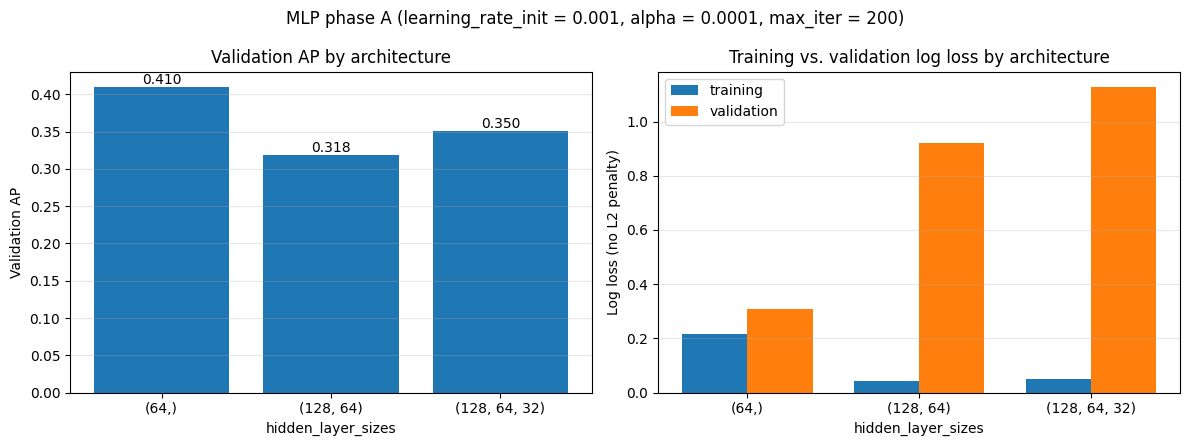

In [29]:
arch_df = mlp_table(phase_a_mlp)
arch_labels = [str(layers) for layers in arch_df["hidden_layer_sizes"]]
positions = np.arange(len(arch_labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(positions, arch_df["valid_AP"], color="tab:blue")
for x, ap in zip(positions, arch_df["valid_AP"]):
    axes[0].annotate(f"{ap:.3f}", (x, ap), ha="center", va="bottom")
axes[0].set_ylabel("Validation AP")
axes[0].set_title("Validation AP by architecture")

width = 0.38
axes[1].bar(positions - width / 2, arch_df["train_logloss"], width, label="training")
axes[1].bar(positions + width / 2, arch_df["valid_logloss"], width, label="validation")
axes[1].set_ylabel("Log loss (no L2 penalty)")
axes[1].set_title("Training vs. validation log loss by architecture")
axes[1].legend()

for ax in axes:
    ax.set_xticks(positions, arch_labels)
    ax.set_xlabel("hidden_layer_sizes")
    ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"MLP phase A (learning_rate_init = {MLP_BASE_PARAMS['learning_rate_init']}, "
             f"alpha = {MLP_BASE_PARAMS['alpha']}, max_iter = {MLP_MAX_ITER})")
fig.tight_layout()
fig.savefig("fig_mlp_architectures.png", dpi=200, bbox_inches="tight")
plt.show()

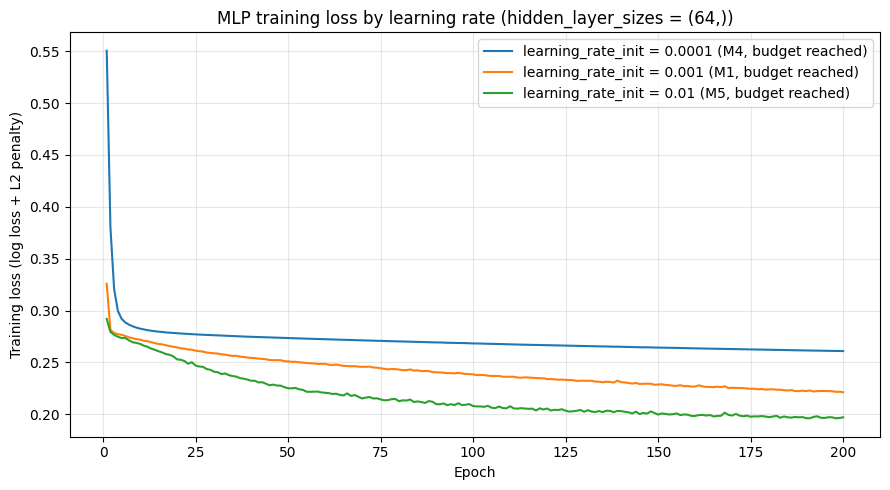

In [30]:
fig, ax = plt.subplots(figsize=(9, 5))
for record in sorted(lr_comparison, key=lambda r: r["learning_rate_init"]):
    curve = mlp_models[record["config"]].loss_curve_
    status = "converged" if record["converged"] else "budget reached"
    ax.plot(range(1, len(curve) + 1), curve,
            label=f"learning_rate_init = {record['learning_rate_init']} ({record['config']}, {status})")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training loss (log loss + L2 penalty)")
ax.set_title(f"MLP training loss by learning rate (hidden_layer_sizes = {best_layers})")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fig_mlp_learning_rates.png", dpi=200, bbox_inches="tight")
plt.show()

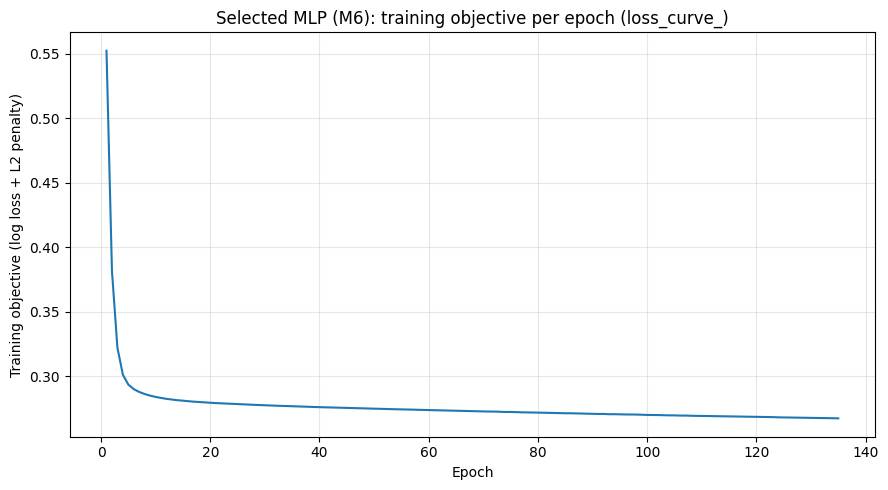

In [31]:
curve = mlp_selected.loss_curve_

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, len(curve) + 1), curve, color="tab:blue")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training objective (log loss + L2 penalty)")
ax.set_title(f"Selected MLP ({MLP_SELECTED_ID}): training objective per epoch (loss_curve_)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fig_mlp_selected_loss.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretation.**

- **More capacity overfits badly under this budget.** At the default learning rate and `alpha`, the two deeper networks drive training log loss to about 0.04–0.05 while validation log loss rises to 0.92–1.13 and validation AP falls to 0.32–0.35. The single 64-unit layer overfits less (gap 0.09, AP 0.41). With `early_stopping=False`, nothing stops training once a network starts memorizing the training rows, so extra width and depth add variance rather than reduce bias. The (128, 64, 32) network "converged" after 150 epochs and still has the worst validation log loss: in scikit-learn, converged only means the training loss flattened, not that the model generalizes.
- **The learning rate decides how far training moves toward overfitting within 200 epochs.** At `0.01` the network reaches the lowest training loss of phase B (0.18) but the highest validation loss (0.48) and AP 0.35. At `0.0001` training is slower and the loss is still decreasing at epoch 200, but the train–validation gap almost disappears (0.008) and AP rises to 0.48. Unlike GBDT, where early stopping made the learning rate mainly a speed setting, here it changes the final model substantially.
- **L2 regularization closes the remaining gap.** With `alpha` 0.01 or 0.1 the gap shrinks to 0.003 and 0.0004, both runs converge after 135 epochs, and validation AP (0.4825 and 0.4810) is essentially tied with the unregularized `0.0001` run (0.4805). `alpha = 1.0` underfits slightly: both losses rise and AP drops to 0.467.
- **Convergence warnings and the `max_iter` budget.** Four of eight runs (M1, M2, M4, M5) used the full 200 epochs and raised a `ConvergenceWarning`: their training loss was still improving by more than `tol`. For M1, M2, and M5 more epochs would most likely increase overfitting, not help. M4's curve is nearly flat by epoch 200 and its AP is within 0.002 of the selected model. The budget is kept fixed so that all configurations are compared under the same training effort.
- **The differences among the best runs are small.** M4, M6, and M7 lie within 0.0015 AP of each other, well within sampling noise for about 700 validation positives. M6 is selected by the fixed rule rather than shown to be uniquely best. Its validation AP (0.4825) is about 0.01 below the selected GBDT (0.4923); the held-out comparison is in Section 7.
- **The selected model's curve** (training objective, including the L2 penalty) drops steeply over the first 10 epochs, then decreases slowly until its improvement falls below `tol` and training stops at epoch 135. The penalty-free training and validation log loss in the results table (0.2656 and 0.2684) are close, so the selected MLP shows no sign of overfitting.
- **Limitation of the sequential design.** The architecture was chosen at the default learning rate and `alpha`, where overfitting dominated. A deeper network might be competitive once trained with a smaller learning rate and L2 penalty; this was not tested in order to keep the search effort comparable to the GBDT experiments.


## 7. Final model comparison and one-time test evaluation

Both final configurations were fixed by validation Average Precision before this section: the GBDT in Section 5.4 and the MLP in Section 6.4. Nothing below changes those choices. The test set is used here for the first and only time.

**Metrics.** Average Precision is computed from positive-class probabilities with `average_precision_score`. Accuracy, precision, recall, and F1 for the positive class use a fixed threshold of 0.5. No threshold is tuned.

**Timing.** Both models are timed on the same CPU runtime. Each selected configuration is refitted three times and the median is reported. Preprocessing time is measured separately (also a median of three runs) and covers fitting on the training rows and transforming training, validation, and test.


### 7.1 Selected configurations

In [32]:
selected_configs = pd.DataFrame({
    "GBDT (XGBoost)": {
        "config": GBDT_SELECTED_ID,
        "hyperparameters": (f"learning_rate={selected_record['learning_rate']}, "
                            f"max_depth={selected_record['max_depth']}, "
                            f"subsample={selected_record['subsample']}"),
        "training length": f"{selected_record['best_iteration'] + 1} trees (early stopping)",
        "valid_logloss": round(selected_record["valid_logloss"], 4),
        "valid_AP": round(selected_record["valid_AP"], 4),
    },
    "MLP": {
        "config": MLP_SELECTED_ID,
        "hyperparameters": (f"hidden_layer_sizes={selected_mlp_record['hidden_layer_sizes']}, "
                            f"learning_rate_init={selected_mlp_record['learning_rate_init']}, "
                            f"alpha={selected_mlp_record['alpha']}"),
        "training length": (f"{selected_mlp_record['epochs']} epochs "
                            f"({'converged' if selected_mlp_record['converged'] else 'budget reached'})"),
        "valid_logloss": round(selected_mlp_record["valid_logloss"], 4),
        "valid_AP": round(selected_mlp_record["valid_AP"], 4),
    },
})
selected_configs

,GBDT (XGBoost),MLP
config,G7,M6
hyperparameters,"learning_rate=0.01, max_depth=4, subsample=0.8","hidden_layer_sizes=(64,), learning_rate_init=0..."
training length,863 trees (early stopping),135 epochs (converged)
valid_logloss,0.266,0.2684
valid_AP,0.4923,0.4825


### 7.2 Training and preprocessing time

Each selected model is refitted three times on the same runtime; the median fit time is reported. Every timed refit is checked to reproduce the selected model. Preprocessing time is measured separately.


In [33]:
TIMING_REPEATS = 3


def timed_refits(estimator, X_fit, fit_kwargs: dict) -> tuple:
    """Refit a fresh copy of `estimator` TIMING_REPEATS times; return every refitted model and its fit time."""
    models, times = [], []
    for _ in range(TIMING_REPEATS):
        model = clone(estimator)
        start = time.perf_counter()
        model.fit(X_fit, y_train, **fit_kwargs)
        times.append(time.perf_counter() - start)
        models.append(model)
    return models, times


gbdt_refits, gbdt_fit_times = timed_refits(
    gbdt_selected, X_train_tree, {"eval_set": [(X_valid_tree, y_valid)], "verbose": False})
mlp_refits, mlp_fit_times = timed_refits(mlp_selected, X_train_mlp, {})

# Every timed refit must reproduce the selected model, since all of them enter the median/min/max.
for refit in gbdt_refits:
    assert refit.best_iteration == gbdt_selected.best_iteration
    assert np.allclose(refit.predict_proba(X_valid_tree), gbdt_selected.predict_proba(X_valid_tree))
for refit in mlp_refits:
    assert np.allclose(refit.predict_proba(X_valid_mlp), mlp_selected.predict_proba(X_valid_mlp))

preprocess_times = {"GBDT (XGBoost)": [], "MLP": []}
for _ in range(TIMING_REPEATS):
    *_, sec = fit_transform_splits(make_preprocessor(scale_numeric=False))
    preprocess_times["GBDT (XGBoost)"].append(sec)
    *_, sec = fit_transform_splits(make_preprocessor(scale_numeric=True))
    preprocess_times["MLP"].append(sec)

timing = pd.DataFrame({
    "preprocessing_sec (median)": {name: np.median(t) for name, t in preprocess_times.items()},
    "fit_sec (median)": {"GBDT (XGBoost)": np.median(gbdt_fit_times), "MLP": np.median(mlp_fit_times)},
    "fit_sec (min)": {"GBDT (XGBoost)": min(gbdt_fit_times), "MLP": min(mlp_fit_times)},
    "fit_sec (max)": {"GBDT (XGBoost)": max(gbdt_fit_times), "MLP": max(mlp_fit_times)},
}).round(3)
print(f"Fit times over {TIMING_REPEATS} refits on {os.cpu_count()} CPU cores "
      f"({platform.platform()}); every timed refit reproduces the selected model.")
timing

Fit times over 3 refits on 2 CPU cores (Linux-6.6.159+-x86_64-with-glibc2.39); every timed refit reproduces the selected model.


,preprocessing_sec (median),fit_sec (median),fit_sec (min),fit_sec (max)
GBDT (XGBoost),0.141,9.994,7.278,10.046
MLP,0.146,27.818,27.631,27.993


### 7.3 Test-set evaluation

In [34]:
THRESHOLD = 0.5

test_proba = {
    "GBDT (XGBoost)": gbdt_selected.predict_proba(X_test_tree)[:, 1],
    "MLP": mlp_selected.predict_proba(X_test_mlp)[:, 1],
}
test_pred = {name: (proba >= THRESHOLD).astype(int) for name, proba in test_proba.items()}
test_prevalence = y_test.mean()

comparison = pd.DataFrame.from_dict({
    name: {
        "validation AP": selected_configs.loc["valid_AP", name],
        "test AP": average_precision_score(y_test, test_proba[name]),
        "test accuracy": accuracy_score(y_test, test_pred[name]),
        "test precision": precision_score(y_test, test_pred[name], zero_division=0),
        "test recall": recall_score(y_test, test_pred[name], zero_division=0),
        "test F1": f1_score(y_test, test_pred[name], zero_division=0),
        "predicted positives": int(test_pred[name].sum()),
        "fit_sec (median)": timing.loc[name, "fit_sec (median)"],
        "preprocessing_sec (median)": timing.loc[name, "preprocessing_sec (median)"],
    }
    for name in test_proba
}, orient="index").round(4)

print(f"Test rows: {len(y_test):,}; actual positives: {int(y_test.sum()):,} "
      f"(positive-class rate {test_prevalence:.4f}); threshold for class metrics: {THRESHOLD}")
comparison

Test rows: 6,179; actual positives: 696 (positive-class rate 0.1126); threshold for class metrics: 0.5


,validation AP,test AP,test accuracy,test precision,test recall,test F1,predicted positives,fit_sec (median),preprocessing_sec (median)
GBDT (XGBoost),0.4923,0.4819,0.9022,0.6917,0.2385,0.3547,240,9.994,0.141
MLP,0.4825,0.4771,0.9003,0.6460,0.2543,0.3649,274,27.818,0.146


### 7.4 Precision–recall curves

The dashed line is the test set's positive-class rate: the precision of a classifier that ranks clients at random. Markers show each model's operating point at the 0.5 threshold.


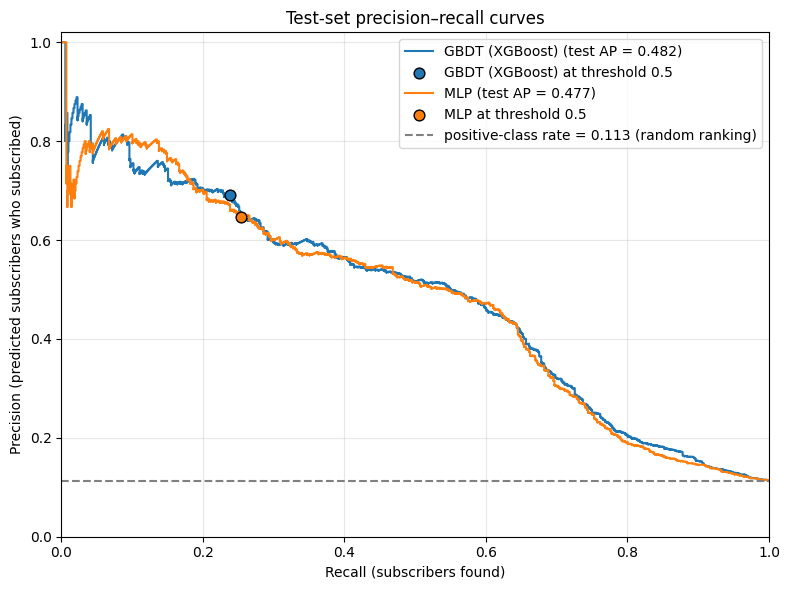

In [35]:
colors = {"GBDT (XGBoost)": "tab:blue", "MLP": "tab:orange"}

fig, ax = plt.subplots(figsize=(8, 6))
for name, proba in test_proba.items():
    precision, recall, _ = precision_recall_curve(y_test, proba)
    ax.plot(recall, precision, drawstyle="steps-post", color=colors[name],
            label=f"{name} (test AP = {comparison.loc[name, 'test AP']:.3f})")
    ax.scatter(comparison.loc[name, "test recall"], comparison.loc[name, "test precision"],
               color=colors[name], edgecolor="black", zorder=5, s=60,
               label=f"{name} at threshold {THRESHOLD}")
ax.axhline(test_prevalence, color="gray", linestyle="--",
           label=f"positive-class rate = {test_prevalence:.3f} (random ranking)")
ax.set_xlabel("Recall (subscribers found)")
ax.set_ylabel("Precision (predicted subscribers who subscribed)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_title("Test-set precision–recall curves")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fig_pr_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### 7.5 Confusion matrices (threshold 0.5)

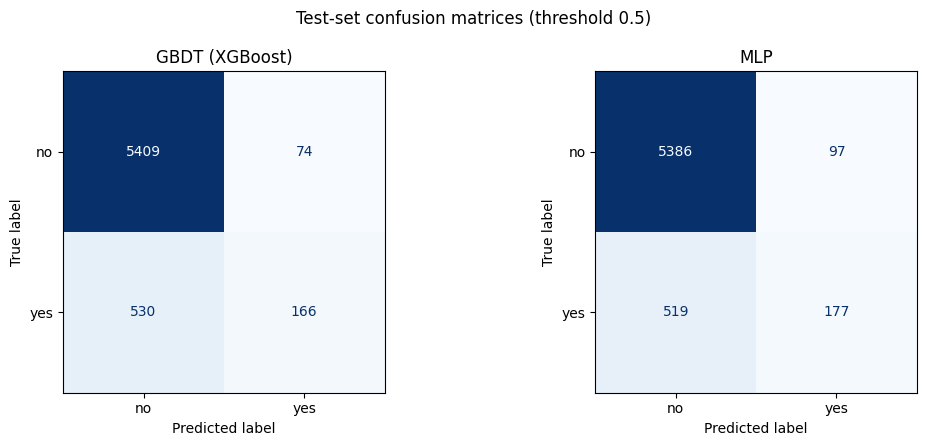

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, test_pred.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1], display_labels=["no", "yes"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name}")
fig.suptitle(f"Test-set confusion matrices (threshold {THRESHOLD})")
fig.tight_layout()
fig.savefig("fig_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

### 7.6 Reproducibility and runtime summary

In [37]:
pd.Series({
    "Python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "xgboost": xgb.__version__,
    "matplotlib": matplotlib.__version__,
    "Platform": platform.platform(),
    "CPU model": cpu_model(),
    "CPU cores": os.cpu_count(),
    "Accelerator": "none (CPU only; XGBoost device=cpu)",
    "Random seed": RANDOM_STATE,
    "Split": "stratified 70/15/15 (train/validation/test)",
    "Selected GBDT": GBDT_SELECTED_ID,
    "Selected MLP": MLP_SELECTED_ID,
    "Timing repeats": TIMING_REPEATS,
}, name="value").to_frame()

,value
Python,3.13.18
pandas,2.2.3
numpy,2.4.6
scikit-learn,1.6.1
xgboost,3.4.1
matplotlib,3.10.0
Platform,Linux-6.6.159+-x86_64-with-glibc2.39
CPU model,Intel(R) Xeon(R) CPU @ 2.20GHz
CPU cores,2
Accelerator,none (CPU only; XGBoost device=cpu)


**Interpretation.**

- **Predictive performance is essentially tied.** Test AP is 0.482 for the GBDT and 0.477 for the MLP. The 0.005 gap is half the validation gap (0.010) and well within sampling noise for 696 test positives. Validation and test AP are close for both models (drops of 0.010 and 0.005), so selecting on validation AP did not noticeably overfit the validation set. The two precision–recall curves overlap almost everywhere and sit far above the random-ranking reference of 0.113.
- **At the fixed 0.5 threshold both models are conservative.** They predict 240 (GBDT) and 274 (MLP) subscribers when 696 actually subscribed, so recall is only about 0.24–0.25. Precision is 0.69 and 0.65. The GBDT is slightly more conservative (74 versus 97 false positives, 166 versus 177 true positives), which is why the MLP has a slightly higher F1 (0.365 versus 0.355) despite a slightly lower AP: threshold metrics depend on where 0.5 falls on each curve, while AP measures ranking over all thresholds. Accuracy (0.902 and 0.900) is only about 1.5 points above the 0.887 majority baseline, which is why accuracy alone is not informative here.
- **The GBDT trains about 2.8× faster.** On the same 2-core CPU runtime, median fit time is 10.0 s for the GBDT (863 trees at learning rate 0.01) versus 27.8 s for the MLP (135 epochs). The three GBDT refits ranged from 7.3 s to 10.0 s. Preprocessing takes about 0.14 s for either model. These timings cover one final fit; each model's eight-configuration search took several times longer.
- **The GBDT reached this level with far less sensitivity to its settings.** Across its eight configurations validation AP ranged only from 0.482 to 0.492, and early stopping chose the number of trees automatically. The MLP ranged from 0.318 to 0.483: at scikit-learn's default learning rate and L2 strength, larger networks overfit badly, and it needed scaled inputs, a smaller learning rate, and L2 regularization to approach the GBDT.
- **When to prefer which.** For a mid-sized tabular dataset like this one — mixed numeric and one-hot categorical features, strong threshold-like effects from a few indicators, about 29,000 training rows — the GBDT is the practical choice: equal or slightly better ranking, faster training, less tuning, no scaling, and a built-in (association-based) feature-importance view. An MLP becomes more attractive when tabular features are combined with text, images, or learned embeddings, when the data are large enough to support more capacity, or when the model must be trained end to end with other neural components. None of those advantages apply here.
- **Limitations.** Results come from one random stratified split and one seed, so differences of a few thousandths of AP are not significant. The split mixes calls from all campaign periods, and the strongest features are calendar-linked macroeconomic indicators, so performance on future campaigns is likely lower than these test scores.


## 8. Summary of findings

| Question | Evidence | Answer |
|---|---|---|
| Which model ranks subscribers better? | Test AP (7.3), PR curves (7.4) | Practically tied: GBDT 0.482 vs. MLP 0.477, both far above the 0.113 no-skill level; the 0.005 gap is within sampling noise |
| How do they behave at the 0.5 threshold? | Confusion matrices (7.5) | Both are conservative (recall about 0.24–0.25, precision 0.65–0.69); the MLP finds slightly more subscribers with more false alarms |
| Which is cheaper to train? | Timing table (7.2) | GBDT, about 2.8× faster on the same CPU runtime; preprocessing is negligible for both |
| Which is more sensitive to tuning? | Tables in 5.4 and 6.4 | The MLP: validation AP 0.32–0.48 across its runs vs. 0.482–0.492 for GBDT |
| What controls overfitting? | Log-loss gaps, learning curves | GBDT: early stopping, shallower trees, and row subsampling. MLP: a smaller learning rate and L2 penalty; extra depth/width overfits at the defaults |
| What does the GBDT rely on? | Total-gain importance (5.6) | Mostly calendar-linked macroeconomic indicators (`nr.employed` about half of the gain); an association, not a causal effect |

**Limitations:**

- One stratified split and one seed; differences of a few thousandths of AP are not significant.
- Tuning was sequential (one factor at a time, 8 runs per model), so interactions such as a deeper MLP with stronger L2 were not tested.
- A random split mixes campaign periods; performance on future campaigns is likely lower.
- The 0.5 threshold was not tuned; a deployment would pick a threshold on validation data from the cost of a call versus the value of a subscription.
- Timings come from a shared CPU runtime and are indicative; the ratio between the models is more reliable than the absolute seconds.
